# Рекомендательные модели

Сравниваю пять методов: KNN (user-based и item-based варианты), implicit ALS, EASE, FM и ALS с кастомным целевым сигналом. В исходном файле Amazon Reviews 2018, категория Digital Music 5-core, 169 781 отзыв. Таблица подготовки данных показывает размер выборки после очистки и отбора объектов.

Одна строка — оценка пользователя (`user_id`) музыкального объекта (`item_id`). `rating` принимает значения от 1 до 5, `timestamp` — время отзыва в Unix time. В таблице объектов есть формат продукта `item_format`; для части товаров он не указан и записан как `unknown`. Признак `context_month` задаёт месяц, известный в момент рекомендации.

Кандидаты — 5 000 объектов, отобранных по положительным train-взаимодействиям. Рейтинг не ниже 4 считается положительным и релевантным. Данные взяты из [Amazon Review Data 2018](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/index.html), напрямую из [файла Digital Music 5-core](https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Digital_Music_5.json.gz). Датасет не относится к запрещённым датасетам семинаров.

Основная метрика — NDCG@10, дополнительная — Recall@10. Параметры выбираются на validation, test используется только для финального сравнения.

In [9]:
import shutil
from pathlib import Path

source_dir = next(Path("/kaggle/input").rglob("prepare_data.py")).parent
shutil.copytree(source_dir, "/kaggle/working", dirs_exist_ok=True)

import numpy as np
import pandas as pd
import scipy.sparse as sparse
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from models.user_knn import UserKNN
from models.item_knn import ItemKNN
from models.als import ALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_ials import CustomTargetALS

torch.manual_seed(0)
device = torch.device("cuda")

%run prepare_data.py

events = pd.read_csv("data/processed/events.csv", dtype={"user_id": str, "item_id": str})
items = pd.read_csv("data/processed/items.csv", dtype={"item_id": str})


<Figure size 640x480 with 0 Axes>

In [10]:
data_summary = pd.DataFrame({
    "interactions": [len(events)],
    "users": [events["user_id"].nunique()],
    "items": [events["item_id"].nunique()],
    "train interactions": [(events["split"] == "train").sum()],
    "validation interactions": [(events["split"] == "validation").sum()],
    "test interactions": [(events["split"] == "test").sum()],
})
data_summary


,interactions,users,items,train interactions,validation interactions,test interactions
0,102794,15887,5000,81417,10827,10550


## EDA и очистка

Повторные отзывы одной пары пользователь–объект сведены к последнему по времени отзыву. Чтобы сравнивать модели на одном и ограниченном по размеру каталоге, оставлены 5 000 наиболее популярных объектов по положительным train-взаимодействиям; validation и test при отборе не используются. Такой размер также позволяет обучить EASE с матрицей объектов 5 000 × 5 000. После фильтрации пользователей без train-истории в выборке 102 794 взаимодействия, 15 887 пользователей и 5 000 объектов. Формат товара извлечён из метаданных отзывов; отсутствующие значения помечены как `unknown`.

In [11]:
preparation_summary


,Этап,Взаимодействия,Пользователи,Объекты
0,Исходные отзывы,169781,16566,11797
1,После удаления дублей,145292,16566,11797
2,После выбора 5 000 объектов,103573,16410,5000
3,После фильтрации пользователей без train,102794,15887,5000


In [12]:
quality_summary = pd.DataFrame({
    "Проверка": [
        "Повторные пары, удалённые при очистке",
        "Повторные пары после очистки",
        "Пропуски в итоговых взаимодействиях",
        "Отзывы без формата в исходных данных",
        "Объекты с неизвестным форматом",
    ],
    "Количество": [
        duplicate_interactions_removed,
        events.duplicated(["user_id", "item_id"]).sum(),
        events.isna().sum().sum(),
        raw_unknown_format_count,
        items["item_format"].eq("unknown").sum(),
    ],
})
quality_summary


,Проверка,Количество
0,"Повторные пары, удалённые при очистке",24489
1,Повторные пары после очистки,0
2,Пропуски в итоговых взаимодействиях,0
3,Отзывы без формата в исходных данных,11792
4,Объекты с неизвестным форматом,301


In [13]:
user_activity = events.groupby("user_id").size()
item_popularity = events.groupby("item_id").size()

activity_summary = pd.DataFrame({
    "Взаимодействия на пользователя": user_activity.describe(),
    "Взаимодействия на объект": item_popularity.describe(),
})
activity_summary.round(2)


,Взаимодействия на пользователя,Взаимодействия на объект
count,15887.00,5000.00
mean,6.47,20.56
std,7.57,21.16
min,1.00,7.00
25%,3.00,11.00
50%,5.00,15.00
75%,7.00,22.00
max,355.00,571.00


In [14]:
matrix_size = events["user_id"].nunique() * events["item_id"].nunique()
density = len(events) / matrix_size

sparsity_summary = pd.DataFrame({
    "Значение": [len(events), matrix_size, density, 1 - density],
}, index=["Взаимодействия", "Возможные пары", "Плотность", "Разреженность"])
sparsity_summary


,Значение
Взаимодействия,1.027940e+05
Возможные пары,7.943500e+07
Плотность,1.294064e-03
Разреженность,9.987059e-01


In [15]:
rating_counts = events["rating"].value_counts().sort_index()
rating_counts


rating
1.0     1195
2.0      996
3.0     3760
4.0    14042
5.0    82801
Name: count, dtype: int64

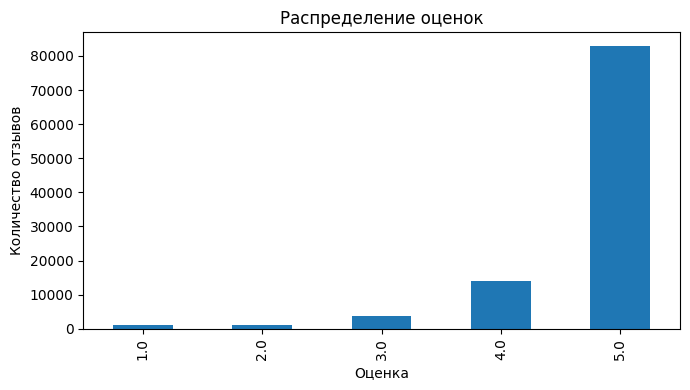

In [16]:
rating_counts.plot(kind="bar", figsize=(7, 4))
plt.xlabel("Оценка")
plt.ylabel("Количество отзывов")
plt.title("Распределение оценок")
plt.tight_layout()
plt.show()


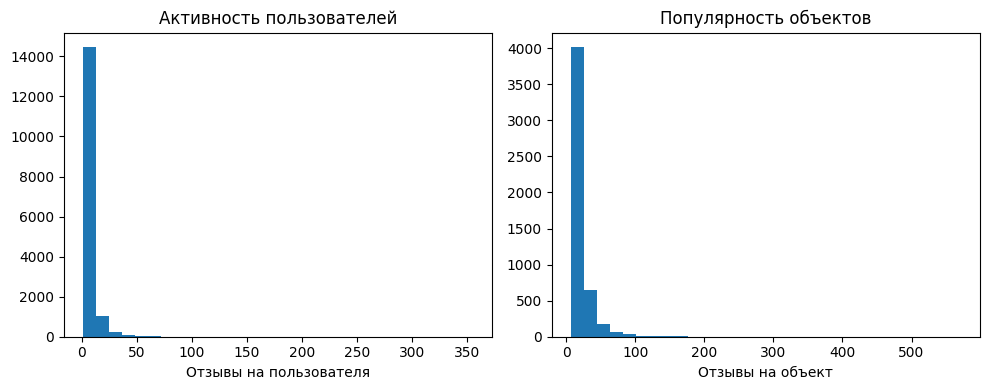

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(user_activity, bins=30)
axes[0].set_title("Активность пользователей")
axes[0].set_xlabel("Отзывы на пользователя")
axes[1].hist(item_popularity, bins=30)
axes[1].set_title("Популярность объектов")
axes[1].set_xlabel("Отзывы на объект")
plt.tight_layout()
plt.show()


In [18]:
format_counts = items["item_format"].value_counts()
format_counts


item_format
MP3 Music    4348
Audio CD      350
unknown       301
DVD             1
Name: count, dtype: int64

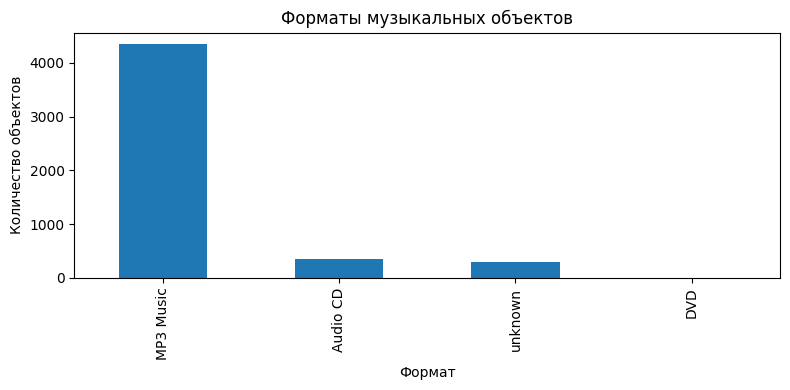

In [19]:
format_counts.head(10).plot(kind="bar", figsize=(8, 4))
plt.xlabel("Формат")
plt.ylabel("Количество объектов")
plt.title("Форматы музыкальных объектов")
plt.tight_layout()
plt.show()


## Протокол оценки

Для каждого пользователя отзывы упорядочиваются по времени: предпоследний отзыв идёт в validation, последний — в test, остальные — в train. Пользователи без train-истории отфильтрованы на этапе подготовки. Кандидаты — те же 5 000 объектов, отобранных по положительным train-взаимодействиям; объекты вне этого каталога не оцениваются. Поэтому cold-start новых пользователей и объектов здесь не проверяется: все оцениваемые пользователи имеют train-историю, а все целевые объекты входят в общий каталог.

Для каждого пользователя из рекомендаций исключаются все объекты, встречавшиеся у него в train. Релевантны held-out отзывы с рейтингом не ниже 4. NDCG@10 учитывает позиции релевантных объектов в списке. Recall@10 показывает, какая доля релевантных объектов попала в первые десять рекомендаций. Основной параметр моделей выбирается по NDCG@10 на validation.

In [20]:
train_all = events[events["split"] == "train"].copy()
validation = events[events["split"] == "validation"].copy()
test = events[events["split"] == "test"].copy()
test

,user_id,item_id,rating,timestamp,split,context_month
28,A0072041HVZ3465DXUOR,B00FY9PGJ2,5.0,1407024000,test,8
41,A1006TXWG76H0N,B00ZRRB8WA,5.0,1454025600,test,1
48,A100UXMXYOQU1X,B00C6MPW12,4.0,1477526400,test,10
57,A101N4D8PRU6N5,B004XRZ8RG,5.0,1362787200,test,3
67,A101PYPZ8ASKCV,B00OXE3A6K,5.0,1424390400,test,11
...,...,...,...,...,...,...
102760,AZX7GXLU4FLAI,B001NU1C44,5.0,1461715200,test,8
102772,AZXWUZ9PPSOTL,B00136NNQ8,4.0,1405382400,test,7
102778,AZY0M1ANDSEPL,B000TPHM5C,5.0,1476230400,test,10
102788,AZYPOLLSDVG4K,B00137GGNE,5.0,1377388800,test,4


In [21]:
user_ids = sorted(train_all["user_id"].unique())
item_ids = sorted(train_all["item_id"].unique())
user_to_index = {user_id: index for index, user_id in enumerate(user_ids)}
item_to_index = {item_id: index for index, item_id in enumerate(item_ids)}

events["user_idx"] = events["user_id"].map(user_to_index)
events["item_idx"] = events["item_id"].map(item_to_index)
train_all = events[events["split"] == "train"].copy()
validation = events[events["split"] == "validation"].copy()
test = events[events["split"] == "test"].copy()
test

,user_id,item_id,rating,timestamp,split,context_month,user_idx,item_idx
28,A0072041HVZ3465DXUOR,B00FY9PGJ2,5.0,1407024000,test,8,0,4006
41,A1006TXWG76H0N,B00ZRRB8WA,5.0,1454025600,test,1,3,4766
48,A100UXMXYOQU1X,B00C6MPW12,4.0,1477526400,test,10,4,3753
57,A101N4D8PRU6N5,B004XRZ8RG,5.0,1362787200,test,3,5,2983
67,A101PYPZ8ASKCV,B00OXE3A6K,5.0,1424390400,test,11,6,4505
...,...,...,...,...,...,...,...,...
102760,AZX7GXLU4FLAI,B001NU1C44,5.0,1461715200,test,8,15881,2328
102772,AZXWUZ9PPSOTL,B00136NNQ8,4.0,1405382400,test,7,15882,1339
102778,AZY0M1ANDSEPL,B000TPHM5C,5.0,1476230400,test,10,15883,244
102788,AZYPOLLSDVG4K,B00137GGNE,5.0,1377388800,test,4,15885,1469


In [22]:
num_users = len(user_ids)
num_items = len(item_ids)
train_positive = train_all[train_all["rating"] >= 4]
interaction_matrix = sparse.csr_matrix(
    (np.ones(len(train_positive)), (train_positive["user_idx"], train_positive["item_idx"])),
    shape=(num_users, num_items),
)
all_train_matrix = sparse.csr_matrix(
    (np.ones(len(train_all)), (train_all["user_idx"], train_all["item_idx"])),
    shape=(num_users, num_items),
)

In [23]:
validation_positive = validation[validation["rating"] >= 4]
test_positive = test[test["rating"] >= 4]

validation_relevant = {}
for user_idx, group in validation_positive.groupby("user_idx"):
    validation_relevant[user_idx] = set(group["item_idx"])

test_relevant = {}
for user_idx, group in test_positive.groupby("user_idx"):
    test_relevant[user_idx] = set(group["item_idx"])

seen_by_user = {}
for user_idx, group in train_all.groupby("user_idx"):
    seen_by_user[user_idx] = set(group["item_idx"])



In [24]:
def evaluate_at_10(model, relevant_by_user, fm=False):
    recall_values = []
    ndcg_values = []

    for user_idx, relevant_items in relevant_by_user.items():
        if fm:
            scores = predict_fm(model, user_idx).copy()
        else:
            scores = model.predict(user_idx).copy()

        for item_idx in seen_by_user[user_idx]:
            scores[item_idx] = -np.inf

        top_items = np.argsort(scores)[-10:][::-1]
        hits = [int(item_idx in relevant_items) for item_idx in top_items]
        recall_values.append(sum(hits) / len(relevant_items))

        dcg = sum(hit / np.log2(rank + 2) for rank, hit in enumerate(hits))
        ideal_hits = min(10, len(relevant_items))
        idcg = sum(1 / np.log2(rank + 2) for rank in range(ideal_hits))
        ndcg_values.append(dcg / idcg)

    return {
        "NDCG@10": np.mean(ndcg_values),
        "Recall@10": np.mean(recall_values),
    }


## Модели и пространство подбора

1. **User-KNN и Item-KNN.** Сходство считается по косинусу. Для User-KNN оценка объекта равна `score(u, i) = Σᵥ sim(u, v) · x(v, i)` по `k` ближайшим пользователям. Для Item-KNN: `score(u, i) = Σⱼ x(u, j) · sim(j, i)` по объектам из истории пользователя. Проверяются `neighbors = 20, 50, 100`.
2. **Implicit ALS.** Положительным взаимодействиям задаётся `p_ui = 1`, остальным — `p_ui = 0`. Для наблюдаемой пары уверенность `c_ui = 1 + alpha`. Обучение минимизирует `Σ_ui c_ui (p_ui − x_uᵀy_i)² + λ(Σ_u ||x_u||² + Σ_i ||y_i||²)`. Проверяются 8 и 16 факторов; `alpha = 40`, `regularization = 0.1`, 8 итераций.
3. **EASE.** Линейные веса вычисляются из `P = (XᵀX + λI)⁻¹`: `B = −P / diag(P)`, после чего диагональ `B` обнуляется. Проверяются `λ = 100, 500`.
4. **FM.** Для признаков используется `ŷ = w₀ + Σᵢ wᵢxᵢ + Σᵢ<ⱼ ⟨vᵢ, vⱼ⟩xᵢxⱼ`. FM обучается на положительных train-парах и случайных объектах, не встречавшихся в train-истории пользователя. Проверяются 8 и 16 факторов; обучение длится 5 эпох.
5. **Кастомный ALS.** Целевой сигнал зависит от оценки и давности отзыва; формула и сравнение с базовым ALS приведены ниже. Проверяются `decay = 0.1, 0.25` и 8, 16 факторов; `alpha = 20`, `regularization = 0.1`, 8 итераций.

Все настройки выбираются по validation. Случайные зерна фиксированы в ноутбуке и моделях. Для каждого метода обучение, ранжирование и оценка реализованы в отдельных файлах `models/`; сторонние готовые рекомендательные алгоритмы не используются.


In [25]:
validation_rows = []
best_models = {}
best_parameters = {}

for model_name, model_class in [("User KNN", UserKNN), ("Item KNN", ItemKNN)]:
    for n_neighbors in [20, 50, 100]:
        model = model_class().fit(interaction_matrix, n_neighbors=n_neighbors)
        metrics = evaluate_at_10(model, validation_relevant)
        validation_rows.append({"Model": model_name, "Parameters": f"neighbors={n_neighbors}", **metrics})

        if model_name not in best_models or metrics["NDCG@10"] > best_parameters[model_name]["NDCG@10"]:
            best_models[model_name] = model
            best_parameters[model_name] = {"NDCG@10": metrics["NDCG@10"], "Parameters": f"neighbors={n_neighbors}"}


In [26]:
for factors in [8, 16]:
    model = ALS().fit(interaction_matrix, factors=factors, iterations=8)
    metrics = evaluate_at_10(model, validation_relevant)
    validation_rows.append({"Model": "ALS", "Parameters": f"factors={factors}", **metrics})

    if "ALS" not in best_models or metrics["NDCG@10"] > best_parameters["ALS"]["NDCG@10"]:
        best_models["ALS"] = model
        best_parameters["ALS"] = {"NDCG@10": metrics["NDCG@10"], "Parameters": f"factors={factors}"}

pd.DataFrame(validation_rows).tail(2)

,Model,Parameters,NDCG@10,Recall@10
6,ALS,factors=8,0.037113,0.069364
7,ALS,factors=16,0.050867,0.092486


In [27]:
for regularization in [100, 500]:
    model = EASE().fit(interaction_matrix, regularization=regularization)
    metrics = evaluate_at_10(model, validation_relevant)
    validation_rows.append({"Model": "EASE", "Parameters": f"regularization={regularization}", **metrics})

    if "EASE" not in best_models or metrics["NDCG@10"] > best_parameters["EASE"]["NDCG@10"]:
        best_models["EASE"] = model
        best_parameters["EASE"] = {"NDCG@10": metrics["NDCG@10"], "Parameters": f"regularization={regularization}"}

pd.DataFrame(validation_rows).tail(2)

,Model,Parameters,NDCG@10,Recall@10
8,EASE,regularization=100,0.101872,0.153032
9,EASE,regularization=500,0.097849,0.148721


## Кастомный целевой сигнал для ALS

Базовый implicit ALS использует цель 1 для каждого положительного взаимодействия. В этой модели цель меняется с учётом оценки и давности отзыва:

*p_ui = ((rating_ui - 3) / 2) × exp(-decay × age_in_years).* 

Высокая оценка даёт положительный сигнал, низкая — отрицательный; старые отзывы влияют слабее. Confidence для наблюдаемых пар остаётся одинаковым, поэтому сравнение проверяет именно новый целевой сигнал. Результат сравнивается с базовым ALS по тем же разбиениям, кандидатам и метрикам.


In [28]:
latest_train_time = train_all["timestamp"].max()
age_in_years = (latest_train_time - train_all["timestamp"]) / (365 * 24 * 60 * 60)
custom_targets = (train_all["rating"].to_numpy() - 3) / 2

for decay in [0.1, 0.25]:
    target_values = custom_targets * np.exp(-decay * age_in_years.to_numpy())
    target_matrix = sparse.csr_matrix(
        (target_values, (train_all["user_idx"], train_all["item_idx"])),
        shape=(num_users, num_items),
    )

    for factors in [8, 16]:
        model = CustomTargetALS().fit(
            all_train_matrix,
            target_matrix,
            factors=factors,
            iterations=8,
            alpha=20,
            regularization=0.1,
        )
        metrics = evaluate_at_10(model, validation_relevant)
        parameters = f"decay={decay}, factors={factors}"
        validation_rows.append({"Model": "Custom ALS", "Parameters": parameters, **metrics})

        if "Custom ALS" not in best_models or metrics["NDCG@10"] > best_parameters["Custom ALS"]["NDCG@10"]:
            best_models["Custom ALS"] = model
            best_parameters["Custom ALS"] = {"NDCG@10": metrics["NDCG@10"], "Parameters": parameters}


## Факторизационная машина

FM использует ID пользователя и объекта, размер истории и среднюю оценку пользователя, формат объекта, число его исторических взаимодействий, среднюю оценку объекта и месяц контекста. Исторические признаки для train считаются только по более ранним отзывам; для validation и test — по train. Оценка, которую нужно предсказать, не используется как признак.


In [29]:
training_feature_rows = train_all.sort_values(["timestamp", "user_idx"]).copy()
training_feature_rows["history_count"] = training_feature_rows.groupby("user_idx").cumcount()
rating_sum_before = training_feature_rows.groupby("user_idx")["rating"].cumsum() - training_feature_rows["rating"]
training_feature_rows["average_rating"] = rating_sum_before / training_feature_rows["history_count"].replace(0, np.nan)
training_feature_rows["average_rating"] = training_feature_rows["average_rating"].fillna(train_all["rating"].mean())

training_feature_rows["item_history_count"] = training_feature_rows.groupby("item_idx").cumcount()
item_rating_sum_before = training_feature_rows.groupby("item_idx")["rating"].cumsum() - training_feature_rows["rating"]
training_feature_rows["item_average_rating"] = item_rating_sum_before / training_feature_rows["item_history_count"].replace(0, np.nan)
training_feature_rows["item_average_rating"] = training_feature_rows["item_average_rating"].fillna(train_all["rating"].mean())


In [30]:
final_user_profile = train_all.groupby("user_idx").agg(
    history_count=("item_idx", "size"),
    average_rating=("rating", "mean"),
).reset_index()
final_item_profile = train_all.groupby("item_idx").agg(
    item_history_count=("rating", "size"),
    item_average_rating=("rating", "mean"),
).reset_index()
final_user_profile.head()

,user_idx,history_count,average_rating
0,0,27,5.0
1,1,5,4.6
2,2,3,5.0
3,3,3,5.0
4,4,5,3.6


In [31]:
item_id_index = train_all[["item_idx", "item_id"]].drop_duplicates("item_idx")
fm_item_info = final_item_profile.merge(item_id_index, on="item_idx", how="left")
fm_item_info = fm_item_info.merge(items[["item_id", "item_format"]], on="item_id", how="left")
fm_item_info["item_popularity_bin"] = np.floor(np.log2(fm_item_info["item_history_count"] + 1)).astype(int).astype(str)
fm_item_info["item_average_rating_bin"] = fm_item_info["item_average_rating"].round().astype(int).astype(str)
fm_item_info["item_format"] = fm_item_info["item_format"].fillna("unknown").astype(str)

user_context = train_all.groupby("user_idx")["timestamp"].max().reset_index()
user_context["context_month"] = pd.to_datetime(user_context["timestamp"], unit="s").dt.month.astype(str)
fm_user_info = final_user_profile.merge(
    user_context[["user_idx", "context_month"]], on="user_idx", how="left"
)
fm_user_info["history_bin"] = np.floor(np.log2(fm_user_info["history_count"] + 1)).astype(int).astype(str)
fm_user_info["average_rating_bin"] = fm_user_info["average_rating"].round().astype(int).astype(str)
fm_user_info.head()

,user_idx,history_count,average_rating,context_month,history_bin,average_rating_bin
0,0,27,5.0,8,4,5
1,1,5,4.6,10,2,5
2,2,3,5.0,2,2,5
3,3,3,5.0,1,2,5
4,4,5,3.6,10,2,4


In [32]:
fm_events = training_feature_rows.merge(items[["item_id", "item_format"]], on="item_id", how="left")
fm_events["history_bin"] = np.floor(np.log2(fm_events["history_count"] + 1)).astype(int).astype(str)
fm_events["average_rating_bin"] = fm_events["average_rating"].round().astype(int).astype(str)
fm_events["item_popularity_bin"] = np.floor(np.log2(fm_events["item_history_count"] + 1)).astype(int).astype(str)
fm_events["item_average_rating_bin"] = fm_events["item_average_rating"].round().astype(int).astype(str)
fm_events["item_format"] = fm_events["item_format"].fillna("unknown").astype(str)
fm_events["context_month"] = fm_events["context_month"].fillna(1).astype(int).astype(str)
fm_events.head()

,user_id,item_id,rating,timestamp,split,context_month,user_idx,item_idx,history_count,average_rating,item_history_count,item_average_rating,item_format,history_bin,average_rating_bin,item_popularity_bin,item_average_rating_bin
0,A1HBI9BBQIG1NH,B001SQAI98,3.0,905040000,train,9,2025,2445,0,4.711178,0,4.711178,Audio CD,0,5,0,5
1,A1PLX7O7HW809U,B001F3FZVK,5.0,919641600,train,2,3006,2091,0,4.711178,0,4.711178,unknown,0,5,0,5
2,A1KCA1O8SPOE8P,B00136NUG6,5.0,932774400,train,7,2358,1349,0,4.711178,0,4.711178,unknown,0,5,0,5
3,AQP1VPK16SVWM,B01929H4VM,5.0,943920000,train,11,14822,4909,0,4.711178,0,4.711178,Audio CD,0,5,0,5
4,A3M88RCAR2T804,B00124DTBK,5.0,946944000,train,1,11007,1139,0,4.711178,0,4.711178,unknown,0,5,0,5


In [33]:
fm_events["user_idx_feature"] = fm_events["user_idx"]
fm_user_info["user_idx_feature"] = fm_user_info["user_idx"]
fm_events["item_idx_feature"] = fm_events["item_idx"] + num_users
fm_item_info["item_idx_feature"] = fm_item_info["item_idx"] + num_users
next_feature_id = num_users + num_items

user_feature_columns = [
    ("history_bin", "history_bin_feature"),
    ("average_rating_bin", "average_rating_bin_feature"),
    ("context_month", "context_month_feature"),
]
for column, feature_column in user_feature_columns:
    values = pd.concat([fm_events[column], fm_user_info[column]])
    codes, categories = pd.factorize(values)
    fm_events[feature_column] = codes[:len(fm_events)] + next_feature_id
    fm_user_info[feature_column] = codes[len(fm_events):] + next_feature_id
    next_feature_id += len(categories)

In [34]:
item_feature_columns = [
    ("item_format", "item_format_feature"),
    ("item_popularity_bin", "item_popularity_bin_feature"),
    ("item_average_rating_bin", "item_average_rating_bin_feature"),
]
for column, feature_column in item_feature_columns:
    values = pd.concat([fm_events[column], fm_item_info[column]])
    codes, categories = pd.factorize(values)
    fm_events[feature_column] = codes[:len(fm_events)] + next_feature_id
    fm_item_info[feature_column] = codes[len(fm_events):] + next_feature_id
    next_feature_id += len(categories)

In [35]:
fm_feature_columns = [
    "user_idx_feature", "item_idx_feature", "history_bin_feature",
    "average_rating_bin_feature", "item_format_feature",
    "item_popularity_bin_feature", "item_average_rating_bin_feature",
    "context_month_feature",
]
fm_train = fm_events[fm_events["rating"] >= 4].copy()
fm_item_info = fm_item_info.set_index("item_idx").reindex(range(num_items))
fm_user_info = fm_user_info.set_index("user_idx").reindex(range(num_users))

positive_features = fm_train[fm_feature_columns].to_numpy(dtype=np.int64)
positive_users = fm_train["user_idx"].to_numpy()
item_features = fm_item_info[[
    "item_idx_feature", "item_format_feature",
    "item_popularity_bin_feature", "item_average_rating_bin_feature",
]].to_numpy(dtype=np.int64)
positive_features[:5]

array([[ 3006, 17978, 20887, 20896, 20914, 20917, 20926, 20902],
       [ 2358, 17236, 20887, 20896, 20914, 20917, 20926, 20903],
       [14822, 20796, 20887, 20896, 20913, 20917, 20926, 20904],
       [11007, 17026, 20887, 20896, 20914, 20917, 20926, 20905],
       [12861, 17688, 20887, 20896, 20914, 20917, 20926, 20905]])

In [36]:
def fit_fm(factors):
    model = FactorizationMachine(next_feature_id, factors=factors).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    rng = np.random.default_rng(0)

    for _ in range(5):
        negative_items = rng.integers(0, num_items, size=len(positive_users))
        for row_number, user_idx in enumerate(positive_users):
            while negative_items[row_number] in seen_by_user[user_idx]:
                negative_items[row_number] = rng.integers(0, num_items)

        negative_features = positive_features.copy()
        negative_features[:, 1] = item_features[negative_items, 0]
        negative_features[:, 4] = item_features[negative_items, 1]
        negative_features[:, 5] = item_features[negative_items, 2]
        negative_features[:, 6] = item_features[negative_items, 3]

        features = np.vstack([positive_features, negative_features])
        labels = np.concatenate([np.ones(len(positive_features)), np.zeros(len(negative_features))])
        order = rng.permutation(len(labels))

        for start in range(0, len(order), 512):
            batch_indices = order[start:start + 512]
            batch_features = torch.tensor(features[batch_indices], dtype=torch.long, device=device)
            batch_labels = torch.tensor(labels[batch_indices], dtype=torch.float32, device=device)
            optimizer.zero_grad()
            logits = model(batch_features)
            loss = F.binary_cross_entropy_with_logits(logits, batch_labels)
            loss.backward()
            optimizer.step()

    return model

In [37]:
def predict_fm(model, user_idx):
    user_row = fm_user_info.loc[user_idx]
    features = np.empty((num_items, len(fm_feature_columns)), dtype=np.int64)
    features[:, 0] = user_row["user_idx_feature"]
    features[:, 1] = fm_item_info["item_idx_feature"].to_numpy(dtype=np.int64)
    features[:, 2] = user_row["history_bin_feature"]
    features[:, 3] = user_row["average_rating_bin_feature"]
    features[:, 4] = fm_item_info["item_format_feature"].to_numpy(dtype=np.int64)
    features[:, 5] = fm_item_info["item_popularity_bin_feature"].to_numpy(dtype=np.int64)
    features[:, 6] = fm_item_info["item_average_rating_bin_feature"].to_numpy(dtype=np.int64)
    features[:, 7] = user_row["context_month_feature"]

    with torch.no_grad():
        features = torch.tensor(features, dtype=torch.long, device=device)
        scores = model(features).cpu().numpy()
    return scores


In [38]:
for factors in [8, 16]:
    model = fit_fm(factors)
    metrics = evaluate_at_10(model, validation_relevant, fm=True)
    parameters = f"factors={factors}, epochs=5"
    validation_rows.append({"Model": "FM", "Parameters": parameters, **metrics})

    if "FM" not in best_models or metrics["NDCG@10"] > best_parameters["FM"]["NDCG@10"]:
        best_models["FM"] = model
        best_parameters["FM"] = {"NDCG@10": metrics["NDCG@10"], "Parameters": parameters}

validation_table = pd.DataFrame(validation_rows).sort_values(
    ["Model", "NDCG@10"], ascending=[True, False]
)
validation_table


,Model,Parameters,NDCG@10,Recall@10
7,ALS,factors=16,0.050867,0.092486
6,ALS,factors=8,0.037113,0.069364
11,Custom ALS,"decay=0.1, factors=16",0.048182,0.085432
13,Custom ALS,"decay=0.25, factors=16",0.046591,0.082786
10,Custom ALS,"decay=0.1, factors=8",0.034350,0.064270
12,Custom ALS,"decay=0.25, factors=8",0.033416,0.062702
8,EASE,regularization=100,0.101872,0.153032
9,EASE,regularization=500,0.097849,0.148721
14,FM,"factors=8, epochs=5",0.006750,0.013520
15,FM,"factors=16, epochs=5",0.006578,0.013520


In [39]:
test_rows = []
for model_name, model in best_models.items():
    if model_name == "FM":
        metrics = evaluate_at_10(model, test_relevant, fm=True)
    else:
        metrics = evaluate_at_10(model, test_relevant)
    test_rows.append({
        "Model": model_name,
        "Parameters": best_parameters[model_name]["Parameters"],
        **metrics,
    })

test_table = pd.DataFrame(test_rows).sort_values("NDCG@10", ascending=False)
test_table


,Model,Parameters,NDCG@10,Recall@10
3,EASE,regularization=100,0.073747,0.115806
0,User KNN,neighbors=100,0.071167,0.111078
1,Item KNN,neighbors=50,0.060071,0.092866
2,ALS,factors=16,0.040651,0.078177
4,Custom ALS,"decay=0.1, factors=16",0.037746,0.071838
5,FM,"factors=8, epochs=5",0.006600,0.013080


### Выводы

На validation лучшим по NDCG@10 оказался EASE с `regularization=100` (0.101872). На test он также показал лучший результат: NDCG@10 — 0.073747, Recall@10 — 0.115806. User-KNN с 100 соседями занял второе место по NDCG@10 на test (0.071167).

Кастомный ALS не превзошёл базовый ALS: на test NDCG@10 составил 0.037746 против 0.040651 у базовой модели. FM с метапризнаками показала самый низкий результат среди сравниваемых методов (NDCG@10 — 0.006600). В этой постановке одних добавленных метаданных и короткого обучения FM оказалось недостаточно.

Ограничения эксперимента: один датасет и один временной split, фиксированный набор из 5 000 популярных кандидатов, короткий подбор параметров и отсутствие оценки статистической значимости. Формат объекта не указан для части товаров. Результаты не обязательно переносятся на другие категории и полный каталог.
